# Tutorial 2: Mouse embryo (E13, spatial-ATAC-seq)

Identify spatial chromatin-accessibility domains in an E13 mouse embryo section and visualize their organization. This example uses spatial ATAC counts, native spatial coordinates and peak–motif associations.

**Original study.** [Deng et al., Nature (2022)](https://doi.org/10.1038/s41586-022-05094-1); [GEO GSE171943](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE171943).

**Output provenance.** Saved outputs document the completed example run; environment labels and paths describe that recorded execution.


## 1. Environment and configuration

Use the [installation guide](../docs/installation.rst) to prepare the tutorial environment, then select the counts, optional motif matrix and output location below. `DATASET` names the run; `CONFIG_PATH` selects the defaults independently. Change the option dictionaries for your data and rerun from this cell after changing configuration.

The `ME13_ATAC_2275.json` profile uses 300 training epochs, 64 embedding dimensions, 20 shards and seed 1234. Analysis requests 17 domains, 20 principal components and 15 Euclidean neighbors; Louvain uses seed 0, and UMAP uses seed 1234 with `min_dist=0.08`. These are configurable analysis and training settings, not inferred biological quantities.

Choose the workflow with `RUN_MODE`:

- `"train"` prepares the network and trains a new model.
- `"provided"` loads `EMBEDDING_DIR` with its matching `ATAC_PATH`, skips network preparation and training, and fits a new downstream analysis.

The example reads bundled peak–motif annotations. Set `MOTIF_OPTIONS["enabled"]=False` for a model with spots and peaks only. Reading an existing motif matrix does not require the R scanner; scanning new annotations requires the reference and dependencies described in step 5.

CUDA training defaults to physical GPU 0; override it with `SEAREG_PHYSICAL_GPU`. For CPU training, set `TRAINING_OPTIONS["device"]="cpu"` and `EXECUTION_OPTIONS["physical_gpu"]=None`, and leave `SEAREG_PHYSICAL_GPU` unset.


In [1]:
from pathlib import Path
from dataclasses import asdict
import hashlib
import json
import os
import sys
import time
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "seareg" / "__init__.py").is_file() and (p / "tutorials").is_dir())
sys.path.insert(0, str(ROOT))
import seareg as sr
sys.path.insert(0, str(ROOT / "tutorials"))
from seareg_tutorial_data import prepare_input_file, create_run_directory
from seareg_tutorial_embeddings import load_tutorial_embeddings

# One input interface: the bundled paths and settings below are editable defaults.
# Keep the profile independent of the run label; a new DATASET needs no new profile.
CONFIG_PATH = ROOT / "tutorials" / "configs" / "ME13_ATAC_2275.json"
profile = json.loads(CONFIG_PATH.read_text())
DATASET = "ME13_ATAC_2275"  # A label for this run.
RUN_MODE = "train"  # "train" or "provided"; rerun from this cell after changing inputs.
ATAC_PATH = (CONFIG_PATH.parent / profile["input"]["atac"]).resolve()
MOTIF_PATH = ((CONFIG_PATH.parent / profile["input"]["dna"]).resolve()
              if profile["input"].get("dna") else None)
EMBEDDING_DIR = ROOT / "result" / "ME13_ATAC_2275" / "training" / "embeddings" / "300_epoch"
OUTPUT_DIR = ROOT / "result" / DATASET  # May be any writable directory.
TARGET_K = profile["analysis"]["target_domains"][0]

# Set enabled=False for counts-only training. With source="auto", a missing
# motif matrix uses the Workflow's R scanner after filtering. Select the actual
# assembly (or counts metadata) and species; fasta may name a local reference.
MOTIF_OPTIONS = {
    "enabled": True,
    "source": "auto",  # "auto", "read", or "scan".
    "genome": os.environ.get("SEAREG_REFERENCE_ASSEMBLY", "").strip() or None,
    "fasta": os.environ.get("SEAREG_REFERENCE_FASTA", "").strip() or None,
    "species_names": [name.strip() for name in os.environ.get(
        "SEAREG_MOTIF_SPECIES", "Homo sapiens,Mus musculus").split(",") if name.strip()],
    "rscript": os.environ.get("SEAREG_RSCRIPT", "Rscript"),
    "threads": 1,
    "auto_build_dna": True,
    "download_reference": True,
}
# Override individual values here, keeping each example's original defaults.
FILTERING_OPTIONS = {**profile["filtering"]}
NETWORK_OPTIONS = {**profile["network"]}
TRAINING_OPTIONS = {**profile["training"]}
ANALYSIS_OPTIONS = {**profile["analysis"]}
EXECUTION_OPTIONS = {**(profile["execution"] if RUN_MODE == "train" else {
    "physical_gpu": None, "torch_threads": 1, "torch_interop_threads": 1,
    "blas_threads": 1, "strict_algorithms": True, "tf32": False,
})}

if RUN_MODE not in {"provided", "train"}:
    raise ValueError("RUN_MODE must be provided or train")
training_config = sr.TrainConfig(**TRAINING_OPTIONS)
analysis_config = sr.AnalysisConfig(**{**ANALYSIS_OPTIONS, "target_domains": (TARGET_K,)})
execution = dict(EXECUTION_OPTIONS)
if RUN_MODE == "train" and "SEAREG_PHYSICAL_GPU" in os.environ:
    execution["physical_gpu"] = int(os.environ["SEAREG_PHYSICAL_GPU"])
print("SEAREG:", sr.__version__)
print("Dataset / mode:", DATASET, RUN_MODE)
if RUN_MODE == "train":
    print("Training device / physical GPU:", training_config.device, execution["physical_gpu"])
    print("Epochs / shards:", training_config.epochs, training_config.shards)
else:
    print("Using the selected embeddings; no model training or GPU is required.")


SEAREG: 0.5.0.dev3
Dataset / device / physical GPU: ME13_ATAC_2275 cuda:0 1
Epochs / shards: 300 20
Loss backend / strict / TF32: auto False False


## 2. Prepare inputs and reserve a new run

Resolve the selected counts file and record its checksum. A missing bundled input can be unpacked from its verified archive; custom inputs must already exist.

In training mode, prepare the optional motif file and configure `sr.Workflow`; motif import or scanning follows filtering in step 5. In provided mode, validate and load the selected embedding export against the counts. Reserve a separate run directory under `OUTPUT_DIR` for the analysis and figures.


In [2]:
def file_sha256(path):
    hasher = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            hasher.update(block)
    return hasher.hexdigest()

def display_path(path):
    path = Path(path).expanduser().resolve()
    return str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path)

# Existing selected files are accepted directly. Only a missing exact bundled
# path can use checked archive extraction; custom paths never select an example.
ATAC_PATH = prepare_input_file(ATAC_PATH, bundle_root=ROOT)
input_hashes = {display_path(ATAC_PATH): file_sha256(ATAC_PATH)}
OUTPUT_DIR = Path(OUTPUT_DIR).expanduser().resolve()
provided_embeddings = None
if RUN_MODE == "provided":
    EMBEDDING_DIR = Path(EMBEDDING_DIR).expanduser().resolve()
    provided_embeddings = load_tutorial_embeddings(EMBEDDING_DIR, counts_path=ATAC_PATH)
elif MOTIF_OPTIONS["enabled"] and MOTIF_PATH is not None and MOTIF_OPTIONS["source"] != "scan":
    MOTIF_PATH = Path(MOTIF_PATH).expanduser().resolve()
    # Transport only: matrix import and scanning occur in step 5, after filtering.
    prepare_input_file(MOTIF_PATH, bundle_root=ROOT, required=False)

# Check chosen counts (and provided exports) before reserving any output.
RUN_DIR = create_run_directory(ROOT, DATASET, RUN_MODE, output=OUTPUT_DIR)
stage_seconds = {}
notebook_started = time.perf_counter()
flow = None
if RUN_MODE == "train":
    inputs = {"atac": str(ATAC_PATH)}
    if MOTIF_OPTIONS["enabled"] and MOTIF_PATH is not None:
        inputs["dna"] = str(Path(MOTIF_PATH).expanduser().resolve())
    motif_options = {key: value for key, value in MOTIF_OPTIONS.items() if value is not None}
    if motif_options.get("fasta"):
        motif_options["fasta"] = str(Path(motif_options["fasta"]).expanduser().resolve())
    if "/" in str(motif_options.get("rscript", "")):
        motif_options["rscript"] = str(Path(motif_options["rscript"]).expanduser().resolve())
    run_profile = {**profile, "schema_version": 2, "dataset_id": DATASET,
                   "input": inputs, "motif": motif_options, "output": str(RUN_DIR),
                   "filtering": FILTERING_OPTIONS, "network": NETWORK_OPTIONS,
                   "training": TRAINING_OPTIONS,
                   "analysis": {**ANALYSIS_OPTIONS, "target_domains": [TARGET_K]},
                   "execution": execution}
    flow = sr.Workflow(run_profile)
    # Capture the actual matrix selected by Workflow, including local auto-discovery.
    selected_motif_path = flow.config["input"].get("dna")
    if selected_motif_path is not None:
        input_hashes[display_path(selected_motif_path)] = file_sha256(selected_motif_path)
print("Run:", display_path(RUN_DIR))
print("Input SHA-256:", input_hashes)


Fresh run: results/ME13_ATAC_2275/github_fresh_20261019T182113Z
Verified input SHA-256: {'data/ME13_ATAC_2275/counts.h5ad': '27ebbf3593f4fb2ae4a1966fb0b910768842aea279bf2aac17e20518a38cf872', 'data/ME13_ATAC_2275/motifs.h5': 'b3fd189521edd4b330a3d5591e5acf8872a224405480ae660f76874283f085bc'}


## 3. Inspect counts and spatial coordinates

Preview a backed matrix slice: rows are spots and columns are genomic peaks. Read spatial coordinates in their native XY orientation.


In [3]:
import anndata as ad
import numpy as np
import pandas as pd

adata = ad.read_h5ad(ATAC_PATH, backed="r")
try:
    print(adata)
    # Select sparse major-axis vectors without materializing the full matrix.
    matrix = adata.X
    if getattr(matrix, "format", None) == "csr":
        block = matrix[np.arange(adata.n_obs) < 5, :5]
    elif getattr(matrix, "format", None) == "csc":
        block = matrix[:5, np.arange(adata.n_vars) < 5]
    else:
        block = matrix[:5, :5]
    values = block.toarray() if hasattr(block, "toarray") else np.asarray(block)
    display(pd.DataFrame(values, index=adata.obs_names[:5], columns=adata.var_names[:5]))
    display(pd.DataFrame(np.asarray(adata.obsm["spatial"])[:5, :2],
                         index=adata.obs_names[:5], columns=["x", "y"]))
finally:
    adata.file.close()
del adata, matrix, block, values


AnnData object with n_obs × n_vars = 2275 × 31285 backed at '/home/disk1/xiemingyu/download/SEAREG/data/ME13_ATAC_2275/counts.h5ad'
    obsm: 'spatial'


,chr1:3670456-3672443,chr1:4491731-4493360,chr1:4571262-4572147,chr1:4785366-4785847,chr1:4807412-4808148
AACGTGATAACGTGAT-1,2,0,0,1,0
AACGTGATAAACATCG-1,0,0,0,0,0
AACGTGATATGCCTAA-1,0,0,0,0,0
AACGTGATAGTGGTCA-1,0,0,0,0,0
AACGTGATACCACTGT-1,0,0,0,0,0


,x,y
AACGTGATAACGTGAT-1,1289,-131
AACGTGATAAACATCG-1,1289,-151
AACGTGATATGCCTAA-1,1289,-171
AACGTGATAGTGGTCA-1,1289,-191
AACGTGATACCACTGT-1,1289,-211


## 4. Filter the count matrix

Filter peaks by chromosome name and the number of spots with nonzero counts using the configured `copy1_frequency_v1` protocol. Save the retained count matrix and peak identities while preserving the spot rows. The displayed shape reports the data available for network construction.

This preparation step runs in training mode; provided mode uses the peak and spot identities of the selected embeddings.


In [4]:
if RUN_MODE == "train":
    started = time.perf_counter()
    filtered = flow.filter()
    stage_seconds["filter_counts"] = time.perf_counter() - started
    if filtered.metadata["source"]["sha256"] != input_hashes[display_path(ATAC_PATH)]:
        raise ValueError("Counts changed between validation and filtering")
    print("Filtered shape:", filtered.metadata["shape"])
    print("Retained peaks:", len(filtered.peak_ids))
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


Filtered shape: (2275, 31284)
Retained peaks: 31284


## 5. Prepare peak–motif annotations

Use `flow.prepare_motif()` to read the selected peak–motif matrix or scan sequences for the retained peaks. These annotations define peak–motif graph connections; they are not tissue or cell-type labels. The preview shows the imported peak and motif axes before network compilation.

The example reads the bundled matrix. For new scans, specify the genome assembly and motif species in the setup cell, optionally provide a reference FASTA, and follow the [motif annotation guide](../docs/motif_annotation.rst) for R and scanner dependencies. Disabling motifs produces a spot–peak model. Provided mode skips this step.


In [5]:
if RUN_MODE == "train":
    started = time.perf_counter()
    selected_motif = flow.prepare_motif()
    stage_seconds["prepare_motif"] = time.perf_counter() - started
    motif_input = {"enabled": flow.config["motif"]["enabled"],
                   "mode": flow.config["motif"]["mode"],
                   "filtered_peak_axis_hash": filtered.metadata["peak_axis_hash"]}
    if selected_motif is None:
        print("Motifs are disabled; the network will contain spots and peaks.")
    else:
        motif_input.update(selected_edges=display_path(selected_motif.path),
                           artifact_fingerprint=selected_motif.fingerprint)
        matrix_path = flow.config["input"].get("dna")
        if "legacy_annotation" in selected_motif.metadata.get("upstreams", {}):
            annotation_artifact = selected_motif.upstream("legacy_annotation", sr.AnnotationResult)
            matrix_path = annotation_artifact.path / "freq_motif.h5"
            motif_input["scanner_provenance"] = display_path(
                annotation_artifact.path / "scanner.provenance.json")
        if matrix_path is not None:
            motif_digest = file_sha256(matrix_path)
            previous_digest = input_hashes.get(display_path(matrix_path), motif_digest)
            if (motif_digest != previous_digest or
                    selected_motif.metadata["source"]["sha256"] != motif_digest):
                raise ValueError("Motif annotation changed between selection and import")
            input_hashes[display_path(matrix_path)] = motif_digest
            motif_input.update(path=display_path(matrix_path), sha256=motif_digest)
        matrix = selected_motif.load_matrix()
        motif_input["source_shape"] = list(matrix.shape)
        print("Peak × motif matrix:", matrix.shape)
        display(pd.DataFrame(matrix[:5, :5].toarray(),
                             index=selected_motif.peak_ids[:5], columns=selected_motif.motif_ids[:5]))
        del matrix
else:
    print("Skipped in provided mode; analysis uses the selected embeddings.")


Peak × motif matrix: (31284, 852)


,PAX6_MA0069_1,RORA_MA0071_1,RXRA_VDR_MA0074_1,REL_MA0101_1,RELA_MA0107_1
chr1_3670456_3672443,0.0,0.0,0.0,0.0,0.0
chr1_4491731_4493360,0.0,0.0,0.0,0.0,0.0
chr1_4571262_4572147,0.0,0.0,0.0,0.0,0.0
chr1_4785366_4785847,0.0,0.0,0.0,0.0,0.0
chr1_4807412_4808148,0.0,0.0,0.0,0.0,0.0


## 6. Build the network

Compile the filtered counts and optional motif annotations into the model network. Align annotations to retained peaks, remove empty motif columns and collapse motif columns with identical retained-peak patterns. The spatial graph connects spots using the configured coordinates and neighborhood rule.

Inspect the final node and edge counts: the motif-node count can be smaller than the imported matrix's column count after this compilation. Training consumes the saved network. Provided mode skips network construction.


In [6]:
if RUN_MODE == "train":
    started = time.perf_counter()
    network = flow.prepare_network()
    stage_seconds["build_network"] = time.perf_counter() - started
    prepared_data = network.load_data()
    node_counts = {"spots": len(prepared_data.spot_ids), "peaks": len(prepared_data.peak_ids),
                   "motifs": len(prepared_data.dna_ids)}
    display(pd.DataFrame([{"entity": key, "nodes": value} for key, value in node_counts.items()]))
    print("Spot–peak / peak–motif edges:", prepared_data.X.nnz,
          prepared_data.dna.nnz if prepared_data.dna is not None else 0)
    graph_report = json.loads((network.path / "graph_report.json").read_text())
    if graph_report["enabled"]:
        display(pd.DataFrame(graph_report["slices"]))
    else:
        print("Spatial graph is disabled for this run.")
    del prepared_data
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


,entity,nodes
0,spots,2275
1,peaks,31284
2,motifs,844


Spot–peak / peak–motif edges: 11933563 495450


,slice,spots,directed_edges
0,sample,2275,97792


## 7. Prepare training inputs

Build the split and sampler inputs from the network. The configured `tr=1.0` uses all observed positive edges for training.


In [7]:
if RUN_MODE == "train":
    started = time.perf_counter()
    training_inputs = flow.prepare_training()
    stage_seconds["prepare_training"] = time.perf_counter() - started
    print("Training-input fingerprint:", training_inputs.fingerprint)
    print("Scientific settings:", {key: getattr(training_config, key) for key in
          ("seed", "epochs", "hidden_dim", "shards", "pn_r", "tr", "spatial_weight", "dna_weight")})
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


Training-input fingerprint: 3cee00a377e4aa0180fe9d4f8ed9cfbf6dc50f8af16deab6449e6197866e2f05
Scientific settings: {'seed': 1234, 'epochs': 300, 'hidden_dim': 64, 'shards': 20, 'pn_r': 10, 'tr': 1.0, 'spatial_weight': 0.5, 'dna_weight': 0.1}


## 8. Initialize and train SEAREG

Submit a new model and optimizer to an independent tmux job and wait for the configured training to finish. The output reports the completed epoch, optimizer updates, backend usage, memory counters and the last five loss-history rows. Use these records to inspect optimization and completion.

The run retains its logs and recovery files; see [training and recovery](../docs/workflow.rst). In provided mode, this cell skips training and the next step selects the previously loaded embeddings.


In [8]:
if RUN_MODE == "train":
    from seareg_tutorial_display import single_line_training_progress
    started = time.perf_counter()
    job = sr.start_training_job(training_inputs, training_config, RUN_DIR / "training",
                                execution=execution, name=DATASET)
    print("Independent training job:", job.path)
    print("Recovery and logs:", job.path / "TRAINING_HANDOFF.md")
    with single_line_training_progress():
        training = job.wait()
    stage_seconds["training_process"] = time.perf_counter() - started
    training_metadata = training.manifest["metadata"]
    print("Final epoch / optimizer updates:", training.final_epoch, training_metadata["optimizer_steps"])
    print("Actual backend steps:", training_metadata["loss_execution"]["backend_step_counts"])
    print("PyTorch peak memory (bytes):", training_metadata["torch_memory"])
    display(pd.read_csv(training.path / "training_history.tsv", sep="\t").tail())
else:
    training = None
    training_metadata = None
    stage_seconds["training_process"] = None
    print("No training was performed. The next cell loads the provided embeddings.")


100%|██████████| 300/300 [04:16<00:00,  1.17it/s]


Final epoch / optimizer updates: 300 6000
Actual backend steps: {'cuda_fused': 6000}
PyTorch peak memory (bytes): {'scope': 'PyTorch allocator since training setup; excludes non-PyTorch allocations', 'peak_allocated_bytes': 6801255424, 'peak_reserved_bytes': 6931087360, 'process_peak_vram_bytes': None, 'process_peak_evidence': 'not_measured_by_allocator_counters'}


,loss,bpr,reg,reg_dna,triplet,epoch,optimizer_steps,nonempty_shards,anchor_pairs,epoch_seconds_excluding_export
295,0.472639,0.448967,23.651819,2.056820,0.0,296,5920,20,0,1.454548
296,0.472479,0.448594,23.864558,2.063031,0.0,297,5940,20,0,0.517134
297,0.472320,0.448221,24.078857,2.068998,0.0,298,5960,20,0,0.520211
298,0.472163,0.447848,24.294689,2.074905,0.0,299,5980,20,0,0.500138
299,0.472006,0.447473,24.512009,2.080777,0.0,300,6000,20,0,0.514915


## 9. Load node embeddings

Select the completed training run's final propagated embeddings, or reuse the export validated in step 2 when `RUN_MODE="provided"`. The loader checks the selected embeddings against the counts' spot and peak identities.

The displayed table lists the available spot, peak and optional motif representations and their dimensions. All following analyses use this same `embeddings` object.


In [9]:
embedding_source = training if RUN_MODE == "train" else EMBEDDING_DIR
if RUN_MODE == "train":
    embeddings = load_tutorial_embeddings(embedding_source, counts_path=ATAC_PATH)
else:
    # Step 2 already validated and loaded these exact selected files before reserving a run.
    embeddings = provided_embeddings
EMBEDDING_DIR = Path(embeddings.provenance["export_path"])
entity_frames = {"spot": embeddings.spot, "peak": embeddings.peak, "motif": embeddings.motif}
analysis_node_counts = {"spots": len(embeddings.spot), "peaks": len(embeddings.peak),
                        "motifs": len(embeddings.motif) if embeddings.motif is not None else 0}
display(pd.DataFrame([
    {"entity": entity, "rows": len(frame), "dimensions": frame.shape[1]}
    for entity, frame in entity_frames.items() if frame is not None
]))
display(embeddings.spot.iloc[:5, :5])

if RUN_MODE == "provided":
    node_counts = dict(analysis_node_counts)


,entity,rows,dimensions
0,spot,2275,64
1,peak,31284,64
2,motif,844,64


,latent_0,latent_1,latent_2,latent_3,latent_4
entity_id,,,,,
AACGTGATAACGTGAT-1,0.038534,-0.290688,0.159478,-0.239019,0.261498
AACGTGATAAACATCG-1,0.003328,-0.389625,0.252115,-0.333933,0.444619
AACGTGATATGCCTAA-1,0.008551,-0.475986,0.353752,-0.385874,0.479462
AACGTGATAGTGGTCA-1,-0.019396,-0.384122,0.228467,-0.316928,0.392672
AACGTGATACCACTGT-1,0.026752,-0.412305,0.088916,-0.359802,0.462525


## 10. Identify domains and fit UMAPs

Run `sr.analyze` on the selected embeddings. For spatial domains, row-normalize spot embeddings, compute PCA, build the configured neighbor graph and search Louvain resolutions for `TARGET_K`. The final search record reports the achieved domain count and resolution. Spot UMAP uses that graph.

Joint UMAP directly fits the concatenated, row-normalized spot, peak and optional motif embeddings. The analysis saves labels, graphs and UMAP coordinates under `RUN_DIR / "analysis"`.

Both training and provided modes perform this fitting step. `TARGET_K` specifies the requested partition size; it is not an automatically estimated number of tissue types.


In [10]:
started = time.perf_counter()
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=execution["blas_threads"]):
    result = sr.analyze(embeddings, analysis_config, RUN_DIR / "analysis", plots=False)
stage_seconds["analysis_process"] = time.perf_counter() - started
domain_result = result.domains(TARGET_K) if analysis_config.domains else None
spot_result = result.spot_embedding() if analysis_config.spot_umap else None
joint_result = result.joint_embedding() if analysis_config.joint else None
if domain_result is not None:
    print("Recomputed spatial domains:", domain_result.target_k)
    print("Final resolution-search step:", domain_result.trace[-1])
    display(domain_result.labels.head())
if joint_result is not None:
    display(joint_result.table.groupby("entity_type").size().rename("nodes"))


Recomputed spatial domains: 17
Final resolution-search step: {'iteration': 6, 'resolution': 1.078125, 'observed_k': 17}


,spot_id,slice_id,domain
0,AACGTGATAACGTGAT-1,sample,D9
1,AACGTGATAAACATCG-1,sample,D9
2,AACGTGATATGCCTAA-1,sample,D9
3,AACGTGATAGTGGTCA-1,sample,D9
4,AACGTGATACCACTGT-1,sample,D9


entity_type
motif      844
peak     31284
spot      2275
Name: nodes, dtype: int64

## 11. Visualize spatial domains

Map the domain labels from step 10 to the spots' native XY coordinates. Domain colors are shared with the spot and joint UMAP views.

Use this map to inspect the spatial extent, boundaries and continuity of the inferred groups. The labels identify computational domains; this cell does not assign anatomical names.


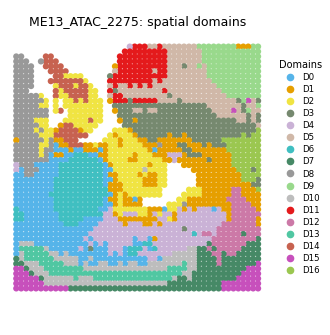

In [11]:
from seareg import plotting
from matplotlib import pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", bbox_inches=None)
figures = {}
if domain_result is not None:
    figures["spatial_domains"], ax = plotting.spatial_domains(
        domain_result.coordinates, domain_result.labels,
        title=f"{DATASET}: spatial domains", point_size=20,
    )
    display(figures["spatial_domains"])
    plt.close(figures["spatial_domains"])


## 12. Spot UMAP

Plot the spot UMAP fitted in step 10 using the same spatial-domain names and colors.


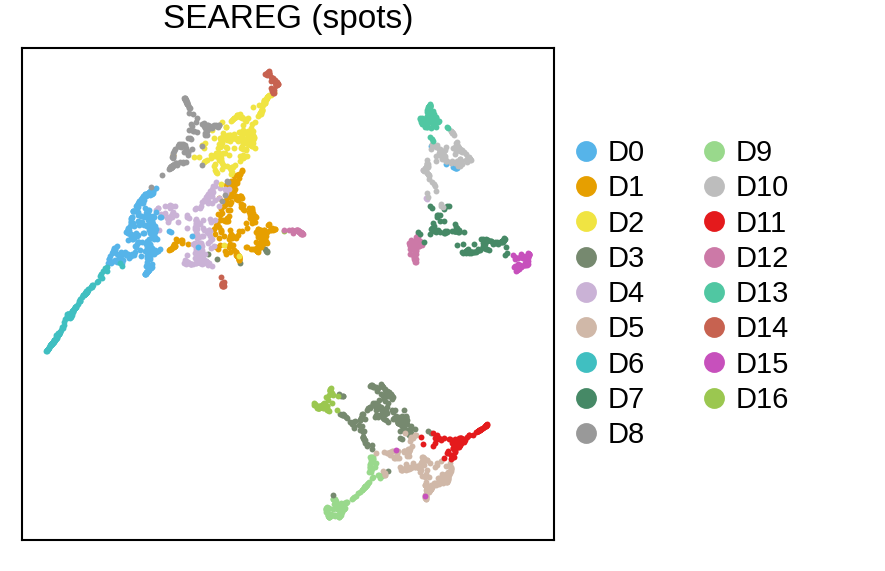

In [12]:
if spot_result is not None:
    figures["spot_umap"], ax = plotting.spot_umap(
        spot_result.table, labels=domain_result.labels if domain_result is not None else None, title="SEAREG (spots)", point_size=2,
    )
    display(figures["spot_umap"], metadata={"image/png": {"width": 950}})
    plt.close(figures["spot_umap"])


## 13. Spot–peak–motif joint UMAP

Display the saved joint coordinates with domain-colored circles for spots, gray triangles for peaks and dark squares for motifs when present. The node types share the representation learned by the model.

Use the layout to inspect relationships among the learned representations. Proximity summarizes embedding similarity and does not by itself establish a regulatory interaction.


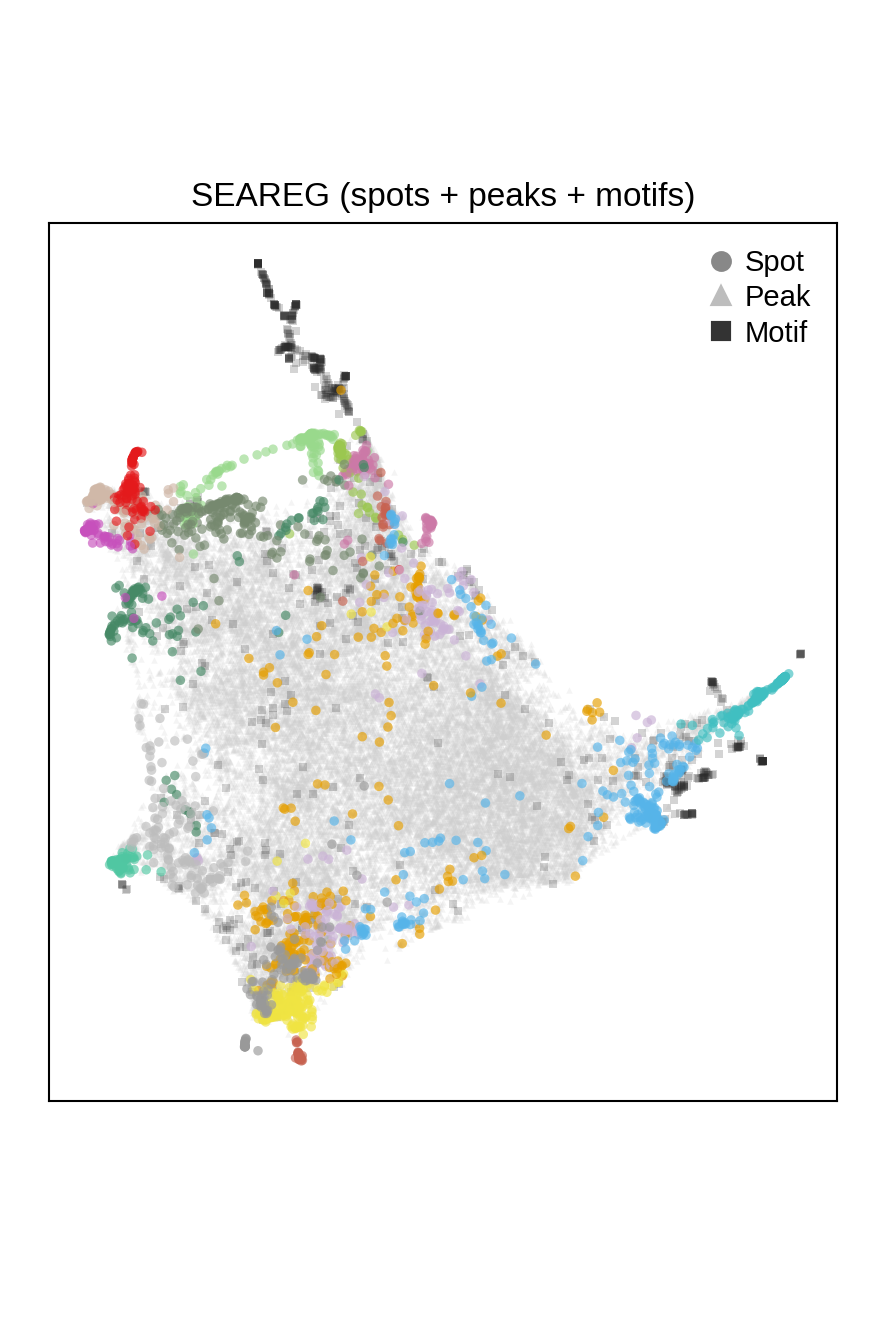

In [13]:
if joint_result is not None:
    figures["joint_umap"], ax = plotting.joint_umap(
        joint_result.table, labels=domain_result.labels if domain_result is not None else None,
        title="SEAREG (spots + peaks + motifs)",
        point_size=5.2, peak_size=2.4, motif_size=4.2,
    )
    display(figures["joint_umap"], metadata={"image/png": {"width": 950}})
    plt.close(figures["joint_umap"])


## 14. Export figures and the execution receipt

Save the spatial-domain, spot-UMAP and joint-UMAP figures as PNG, editable PDF and SVG files. `tutorial_execution.json` records the selected inputs and embeddings, configuration, analysis, and available training statistics.

To inspect this analysis later without retraining or refitting, use `seareg.analysis.load_result(RUN_DIR / "analysis")` and its `domains(TARGET_K)`, `spot_embedding()` and `joint_embedding()` methods. This reads the saved analysis; selecting provided mode instead fits a new analysis from embeddings. See [saved results and recovery](../docs/workflow.rst).


In [14]:
# Read training metadata for the export receipt.
training_metadata = (json.loads((training.path / "status.json").read_text())
                     if RUN_MODE == "train" else None)
figure_directory = RUN_DIR / "figures"
exports_started = time.perf_counter()
saved_figures = []
for name, fig in figures.items():
    is_embedding = name in {"spot_umap", "joint_umap"}
    paths = plotting.save_figure(fig, figure_directory / name,
                               dpi=300 if is_embedding else 450,
                               bbox_inches=None if is_embedding else "tight")
    saved_figures.extend({"figure": name, "file": path.name} for path in paths)
    plt.close(fig)
package_root = Path(sr.__file__).parent
source_hashes = {str(path.relative_to(package_root)): hashlib.sha256(path.read_bytes()).hexdigest()
                 for path in sorted(package_root.rglob("*.py"))}
receipt = {
    "dataset_id": DATASET, "package_version": sr.__version__, "fresh_training": RUN_MODE == "train", "run_mode": RUN_MODE,
    "run": display_path(RUN_DIR), "training": display_path(training.path) if training is not None else None,
    "analysis": display_path(result.path), "input_sha256": input_hashes,
    "configuration_profile": display_path(CONFIG_PATH), "configuration_profile_sha256": file_sha256(CONFIG_PATH),
    "analysis_config": asdict(analysis_config), "target_k": TARGET_K,
    "analysis_manifest_sha256": file_sha256(result.path / "analysis_manifest.json"),
    "embedding_directory": display_path(EMBEDDING_DIR),
    "training_config": asdict(training_config) if training is not None else None,
    "motif_annotation": motif_input if RUN_MODE == "train" else None,
    "analysis_embedding_input": embeddings.provenance, "analysis_nodes": analysis_node_counts,
    "source_sha256": source_hashes, "nodes": node_counts, "epochs": training.final_epoch if training is not None else None,
    "optimizer_steps": training_metadata["optimizer_steps"] if training_metadata is not None else None, "stage_seconds": stage_seconds,
    "execution_seconds_before_exports": exports_started - notebook_started,
    "execution": execution, "loss_execution": training_metadata["loss_execution"] if training_metadata is not None else None,
    "torch_memory": training_metadata["torch_memory"] if training_metadata is not None else None,
}
(RUN_DIR / "tutorial_execution.json").write_text(json.dumps(receipt, indent=2) + "\n")
display(pd.DataFrame(saved_figures))
print("Execution record: tutorial_execution.json")


,figure,file
0,spatial_domains,spatial_domains.png
1,spatial_domains,spatial_domains.pdf
2,spatial_domains,spatial_domains.svg
3,spot_umap,spot_umap.png
4,spot_umap,spot_umap.pdf
5,spot_umap,spot_umap.svg
6,joint_umap,joint_umap.png
7,joint_umap,joint_umap.pdf
8,joint_umap,joint_umap.svg


Execution record: tutorial_execution.json
